# 05 — Regime & Krisis

**Phase 5/7 — Rolling correlation & regime krisis.** Korelasi rata-rata 2010–2019 (Phase 3) menyembunyikan dua hal yang penting bagi investor: apakah keterkaitan IHSG dengan pasar lain **berubah dari waktu ke waktu**, dan bagaimana IHSG berperilaku **justru saat pasar sedang panik**. Phase ini menjawabnya dengan empat alat:
1. Rolling correlation 52 dan 156 minggu.
2. Event study enam guncangan global, dengan satu aturan jendela yang sama untuk semuanya.
3. Quantile regression untuk hipotesis Brent: apakah minyak baru terasa di minggu ekstrem?
4. Perilaku aset pelindung (emas, Dollar Index, yield US 10Y) saat IHSG jatuh.

**Aturan Phase 5 (README, dikunci 23 Okt 2026):** analisis boleh memakai seluruh periode, tetapi **DESKRIPTIF**. Tidak ada temuan di sini yang boleh mengubah Spesifikasi Phase 6.

Hal-hal yang sudah ditetapkan:
- Jangkar dan jendela [−20, +60] hari bursa mengikuti README.
- Jangkar 5 Feb 2018 dijalankan sebagai sensitivitas.
- Okt 2026 hanya deskriptif dan dikeluarkan dari ringkasan lintas episode.
- Harga USD/IDR basi dibuang di analisis harian.
- Brent berlabel "dipilih dengan pengetahuan periode uji".

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import analysis as an
from src import leadlag as ll
from src import plots
from src import preprocess as pp
from src import regime as rg
from src.config import load_config, output_dir, series_table
from src.data_loader import close_panel, load_prices

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

cfg = load_config()
rcfg = cfg["regime"]
series = series_table(cfg, groups=("target", "core", "tools"))
havens_tab = series_table(cfg, groups=("target", "nanti"))
havens_tab = havens_tab[havens_tab["group"].eq("target") | havens_tab["id"].isin(rcfg["safe_haven_ids"])]
target_id, fx_id = cfg["project"]["target_id"], cfg["usdidr_retest"]["id"]
core = [s["id"] for s in cfg["core"]]
names = dict(zip(series["id"], series["name"])) | dict(zip(havens_tab["id"], havens_tab["name"]))
labels = series.set_index("id")["label"]
transforms = dict(zip(series["id"], series["transform"])) | dict(zip(havens_tab["id"], havens_tab["transform"]))
window = tuple(rcfg["window_days"])

dec2 = json.loads((output_dir(cfg, "reports", "phase2") / "decisions.json").read_text())
proc = output_dir(cfg, "data/processed")
prices = pd.read_parquet(proc / "prices_clean.parquet")
flags = pd.read_parquet(proc / "stale_quote_flags.parquet")
weekly = pd.read_parquet(proc / "weekly_returns.parquet")
close = ll.drop_flagged(prices, flags)                          # keputusan Phase 4: kuotasi basi dibuang (harian)
daily = pp.pair_daily_returns(close, target_id, transforms)
trading_days = close[target_id].dropna().index
print(f"Data: {trading_days.min():%d %b %Y} s/d {trading_days.max():%d %b %Y} ({len(trading_days):,} hari bursa IHSG)")

Data: 02 Jan 2007 s/d 21 Oct 2026 (4,797 hari bursa IHSG)


## 1. Rolling correlation mingguan (52 & 156 minggu)

Area abu-abu menandai jendela tujuh episode, termasuk Okt 2026.

Pertanyaan utamanya: pergeseran pasca-2020 yang terlihat di Phase 3 (Hang Seng melemah, S&P 500 menguat), apakah itu **tren** (bertahan sampai sekarang dan terlihat juga di jendela 156 minggu yang lambat) atau **lonjakan sesaat** (hanya di 2020–2022 lalu kembali)?

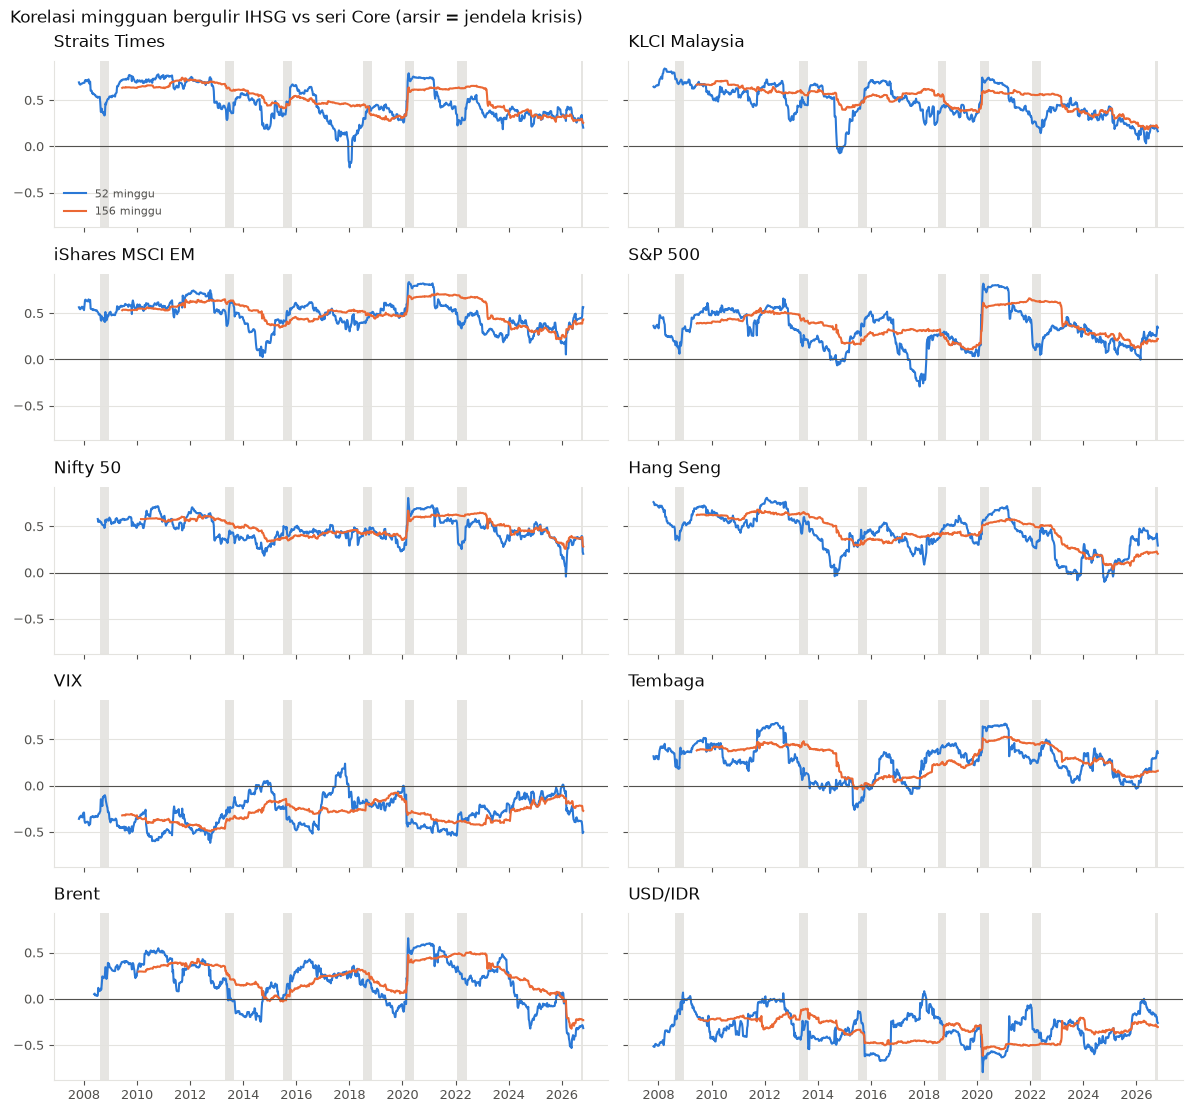

In [2]:
rolls = {w: rg.rolling_corr(weekly, target_id, core, w, rcfg["rolling_min_frac"]) for w in rcfg["rolling_weeks"]}
all_anchors = rcfg["episodes"] | rcfg["descriptive_only"]
wins = {k: rg.episode_window(trading_days, a, window) for k, a in all_anchors.items()}
fig = plots.plot_rolling_corr(rolls, names, [(w.start, w.end) for w in wins.values()],
                              "Korelasi mingguan bergulir IHSG vs seri Core (arsir = jendela krisis)")

In [3]:
shift = {w: rg.rolling_shift_summary(r, rcfg["post_break"], split_years=3, pre_start=cfg["project"]["screening_window"][0])
         for w, r in rolls.items()}
print(shift[52].attrs["periode"])
pd.concat(shift, axis=1).round(2)

pra < 2020-01-01; pasca awal 2020-2022; pasca akhir 2023-sekarang


52                                                                                                          156                                                                         \
       rata_pra rata_pasca_awal rata_pasca_akhir terakhir porsi_pasca_di_bawah_p10_pra porsi_pasca_di_atas_p90_pra rata_pra rata_pasca_awal rata_pasca_akhir terakhir porsi_pasca_di_bawah_p10_pra   
id                                                                                                                                                                                                   
STI        0.47            0.53             0.34     0.20                         0.00                        0.13     0.54            0.61             0.36     0.25                         0.29   
KLCI       0.48            0.48             0.30     0.16                         0.32                        0.10     0.55            0.56             0.33     0.20                         0.53   
EEM        0.50            0.60             0.33     0.57                         0.27                        0.15     0.52            0.67             0.36     0.43                         0.42   
SPX        0.28            0.49             0.24     0.34                         0.00                        0.16     0.34            0.58             0.27     0.22                         0.07   
NIFTY      0.45            0.56             0.39     0.20                         0.13                        0.16     0.48            0.60             0.44     0.28                         0.13   
HSI        0.45            0.48             0.18     0.29                         0.38                        0.04     0.49            0.52             0.19     0.20                         0.53   
VIX       -0.27           -0.39            -0.20    -0.50                         0.05                        0.01    -0.30           -0.35            -0.25    -0.27                         0.00   
COPPER     0.23            0.45             0.17     0.35                         0.00                        0.15     0.26            0.47             0.21     0.16                         0.00   
BRENT      0.19            0.38            -0.00    -0.32                         0.15                        0.25     0.23            0.43             0.12    -0.23                         0.13   
USDIDR    -0.31           -0.40            -0.32    -0.26                         0.16                        0.02    -0.32           -0.49            -0.32    -0.31                         0.43   

                                    
       porsi_pasca_di_atas_p90_pra  
id                                  
STI                           0.00  
KLCI                          0.00  
EEM                           0.41  
SPX                           0.44  
NIFTY                         0.42  
HSI                           0.00  
VIX                           0.14  
COPPER                        0.37  
BRENT                         0.45  
USDIDR                        0.00

## 2. Event study: enam guncangan global

Untuk tiap episode, jendelanya [−20, +60] hari bursa IHSG di sekitar jangkar; hari 0 adalah hari bursa IHSG pertama ≥ tanggal jangkar. Metrik per seri:
- **Drawdown maksimum** di dalam jendela (puncak ke lembah).
- **Hari menuju titik terendah:** hari bursa IHSG dari hari 0 ke harga terendah seri itu sesudah jangkar.
- **Return kumulatif +60:** dari close terakhir sebelum hari 0 sampai akhir jendela.
- **Korelasi harian** (hari yang sama, tanggal sama-sama buka) di dalam jendela vs 250 hari bursa sebelum jendela ("setahun sebelum"), diuji dengan Fisher z. Korelasi dengan periode "normal" (di luar semua jendela) ditampilkan sebagai pembanding dari rencana awal.

EEM tutup setelah IHSG, jadi korelasi hari yang sama meremehkan hubungannya (Phase 3–4). Yang dibandingkan di sini adalah **perubahan** korelasinya, bukan levelnya.

Setiap seri memakai harga di hari bursanya sendiri, tanpa forward-fill.

In [4]:
main, desc = rcfg["episodes"], rcfg["descriptive_only"]
normal = rg.normal_day_mask(trading_days, list(wins.values()))
es = rg.event_study(close, daily, target_id, rcfg["event_ids"], main | desc, window, rcfg["pre_days"], normal)
metric_cols = ["max_drawdown", "hari_ke_titik_terendah", "return_ke_titik_terendah", "return_kumulatif_akhir"]
corr_cols = ["r_setahun_sebelum", "r_jendela", "p_fisher", "r_normal"]
view = es.set_index(["episode", "id"])[metric_cols + corr_cols]
view.loc[list(main)].round(3)

max_drawdown  hari_ke_titik_terendah  return_ke_titik_terendah  return_kumulatif_akhir  r_setahun_sebelum  r_jendela  p_fisher  r_normal
episode id                                                                                                                                            
2008    JKSE        -0.487                      24                    -0.384                  -0.251                NaN        NaN       NaN       NaN
        KLCI        -0.246                      25                    -0.206                  -0.157              0.627      0.667     0.603     0.484
        STI         -0.428                      22                    -0.377                  -0.300              0.671      0.738     0.304     0.533
        EEM         -0.549                      41                    -0.500                  -0.306              0.267      0.273     0.961     0.262
2013    JKSE        -0.200                      60                    -0.196                  -0.196                NaN        NaN       NaN       NaN
        KLCI        -0.050                      60                    -0.037                  -0.037              0.434      0.548     0.253     0.484
        STI         -0.110                      22                    -0.107                  -0.103              0.564      0.614     0.564     0.533
        EEM         -0.171                      22                    -0.156                  -0.109              0.307      0.315     0.943     0.262
2015    JKSE        -0.160                      32                    -0.132                  -0.038                NaN        NaN       NaN       NaN
        KLCI        -0.122                       8                    -0.074                   0.019              0.402      0.645     0.010     0.484
        STI         -0.174                      33                    -0.128                  -0.058              0.360      0.755     0.000     0.533
        EEM         -0.193                       8                    -0.151                  -0.044              0.078      0.506     0.000     0.262
2018    JKSE        -0.068                      16                    -0.063                  -0.021                NaN        NaN       NaN       NaN
        KLCI        -0.079                      52                    -0.068                  -0.050              0.305      0.485     0.110     0.484
        STI         -0.112                      54                    -0.108                  -0.079              0.341      0.418     0.490     0.533
        EEM         -0.156                      53                    -0.139                  -0.057              0.116      0.386     0.026     0.262
2020    JKSE        -0.337                       9                    -0.246                  -0.077                NaN        NaN       NaN       NaN
        KLCI        -0.210                       6                    -0.147                   0.048              0.415      0.623     0.030     0.484
        STI         -0.307                       8                    -0.211                  -0.077              0.379      0.711     0.000     0.533
        EEM         -0.316                       8                    -0.221                   0.006              0.300      0.433     0.240     0.262
2022    JKSE        -0.093                      47                    -0.047                   0.026                NaN        NaN       NaN       NaN
        KLCI        -0.054                      53                    -0.035                  -0.030              0.222      0.551     0.003     0.484
        STI         -0.085                       6                    -0.072                  -0.049              0.282      0.570     0.006     0.533
        EEM         -0.209                      46                    -0.170                  -0.103              0.279      0.328     0.682     0.262

In [5]:
med = rg.summarize_episodes(es, list(desc), metric_cols + corr_cols)
sens_anchors = main | rcfg["sensitivity"]
es_sens = rg.event_study(close, daily, target_id, rcfg["event_ids"], sens_anchors, window, rcfg["pre_days"], normal)
med_sens = rg.summarize_episodes(es_sens, [], metric_cols + corr_cols)
print("Median lintas episode:", med.attrs["episode"])
display(med.round(3))
print("Sensitivitas: jangkar 2018 = " + rcfg["sensitivity"]["2018"])
display(med_sens.round(3))
print("Episode 2018 dengan jangkar 5 Feb (sensitivitas):")
es_sens[es_sens["episode"] == "2018"].set_index("id")[metric_cols + corr_cols].round(3)

Median lintas episode: ['2008', '2013', '2015', '2018', '2020', '2022']


,max_drawdown,hari_ke_titik_terendah,return_ke_titik_terendah,return_kumulatif_akhir,r_setahun_sebelum,r_jendela,p_fisher,r_normal
id,,,,,,,,
EEM,-0.201,31.5,-0.163,-0.080,0.273,0.357,0.461,0.262
JKSE,-0.180,28.0,-0.164,-0.058,NaN,NaN,NaN,NaN
KLCI,-0.100,38.5,-0.071,-0.034,0.409,0.587,0.070,0.484
STI,-0.143,22.0,-0.118,-0.078,0.370,0.662,0.155,0.533


Sensitivitas: jangkar 2018 = 2018-02-05


,max_drawdown,hari_ke_titik_terendah,return_ke_titik_terendah,return_kumulatif_akhir,r_setahun_sebelum,r_jendela,p_fisher,r_normal
id,,,,,,,,
EEM,-0.201,15.0,-0.163,-0.080,0.273,0.322,0.461,0.262
JKSE,-0.180,39.5,-0.164,-0.097,NaN,NaN,NaN,NaN
KLCI,-0.088,16.5,-0.056,-0.020,0.409,0.587,0.039,0.484
STI,-0.142,22.0,-0.118,-0.068,0.370,0.662,0.003,0.533


Episode 2018 dengan jangkar 5 Feb (sensitivitas):


,max_drawdown,hari_ke_titik_terendah,return_ke_titik_terendah,return_kumulatif_akhir,r_setahun_sebelum,r_jendela,p_fisher,r_normal
id,,,,,,,,
JKSE,-0.124,60,-0.116,-0.116,NaN,NaN,NaN,NaN
KLCI,-0.032,1,-0.031,-0.010,0.313,0.525,0.049,0.484
STI,-0.075,40,-0.054,0.013,0.074,0.480,0.001,0.533
EEM,-0.123,3,-0.069,-0.058,0.159,-0.006,0.204,0.262


### Okt 2026: DESKRIPTIF saja

Jangkar 16 Okt 2026 diambil dari IHSG sendiri, dan datanya berakhir beberapa hari setelah jangkar. Jendelanya **terpotong oleh akhir data**: "return kumulatif +60" sebenarnya adalah return sampai hari terakhir yang tersedia. Episode ini **tidak masuk** median maupun perbandingan lintas episode.

In [6]:
d26 = es[es["episode"].isin(desc)].set_index(["episode", "id"])
print("Terpotong:", bool(d26["terpotong"].all()), "| akhir data jendela:", d26["akhir"].iloc[0].date())
d26[["hari_0", "akhir"]].join(d26[metric_cols + ["r_setahun_sebelum", "r_jendela"]].astype(float).round(3))

Terpotong: True | akhir data jendela: 2026-10-21


hari_0      akhir  max_drawdown  hari_ke_titik_terendah  return_ke_titik_terendah  return_kumulatif_akhir  r_setahun_sebelum  r_jendela
episode id                                                                                                                                              
2026    JKSE 2026-10-16 2026-10-21        -0.224                     1.0                    -0.148                  -0.091                NaN        NaN
        KLCI 2026-10-16 2026-10-21        -0.052                     1.0                    -0.017                  -0.013              0.312      0.320
        STI  2026-10-16 2026-10-21        -0.057                     2.0                     0.000                   0.006              0.294      0.018
        EEM  2026-10-16 2026-10-21        -0.090                     0.0                    -0.017                  -0.010              0.109      0.243

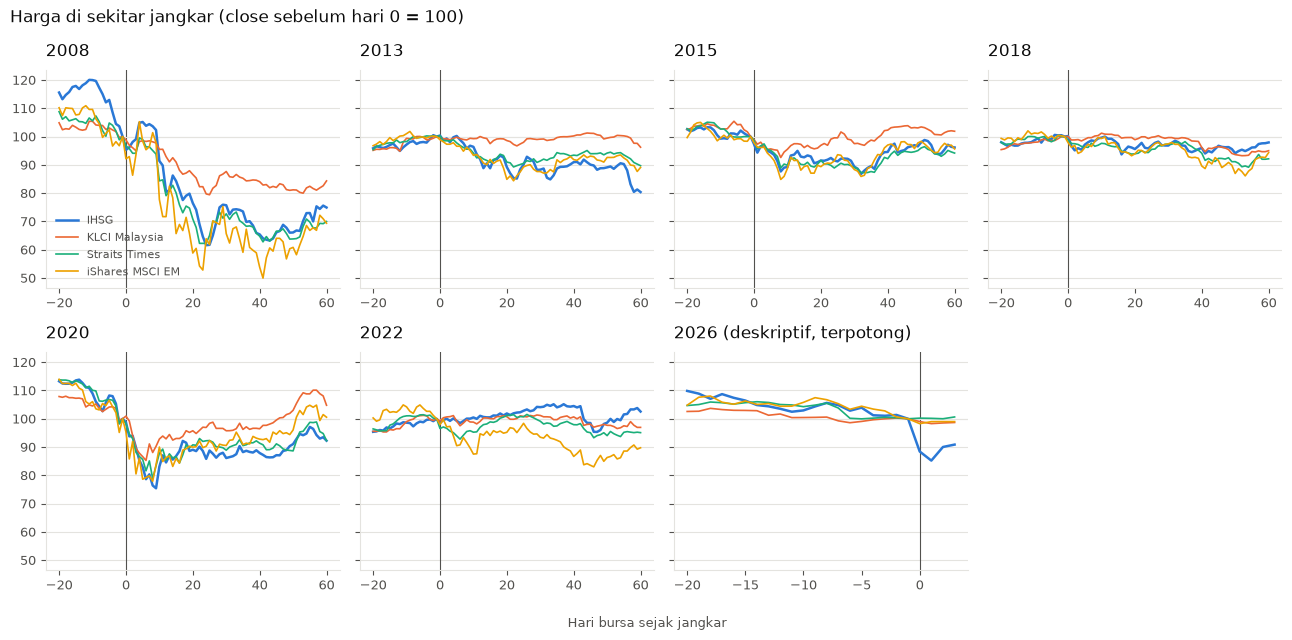

In [7]:
paths = {k: rg.event_paths(close, [target_id] + rcfg["event_ids"], w, trading_days) for k, w in wins.items()}
notes = {k: "deskriptif, terpotong" for k in desc}
fig = plots.plot_event_paths(paths, names, "Harga di sekitar jangkar (close sebelum hari 0 = 100)", notes=notes)

## 3. Hipotesis Brent: quantile regression

Model: return mingguan IHSG ~ Brent + Tembaga + EEM. Tembaga dan EEM adalah kontrol permintaan global; tanpa keduanya, Brent bisa sekadar mewakili "ekonomi dunia sedang bagus".

Regresi dijalankan di kuantil 0,1 sampai 0,9 dari distribusi return IHSG, dengan SE robust. Garis putus-putus menunjukkan OLS. Periodenya 2010–2019 dan seluruh periode.

Pelengkap (sesuai rencana yang dikunci): regresi HAC dengan interaksi Brent × 1[minggu lonjakan Brent], dengan lonjakan = return mingguan Brent di atas persentil 90 periode 2010–2019. Interaksi ini menguji apakah **tandanya berbalik** saat minyak melonjak.

**Semua hasil Brent berlabel "dipilih dengan pengetahuan periode uji".**

In [8]:
brent = rcfg["brent_id"]
xs = [brent] + rcfg["qr_controls"]
qr_periods = {"2010-2019": tuple(cfg["project"]["screening_window"]), "seluruh periode": (None, None)}
qr = {k: rg.quantile_regression(weekly, target_id, xs, rcfg["quantiles"], *v) for k, v in qr_periods.items()}
thr = float(np.nanpercentile(weekly.loc[slice(*cfg["project"]["screening_window"]), brent], rcfg["brent_spike_pct"]))
spikes = {k: rg.spike_interaction(weekly, target_id, brent, rcfg["qr_controls"], thr, *v) for k, v in qr_periods.items()}
print(f"Ambang lonjakan Brent (persentil {rcfg['brent_spike_pct']} 2010-2019): {thr:+.2%} per minggu | label: {labels[brent]}")
pd.concat({k: v[v["variabel"] == brent].set_index("kuantil")[["beta", "ci_lo", "ci_hi", "p", "p_bh", "n"]]
           for k, v in qr.items()}, axis=1).round(4)

Ambang lonjakan Brent (persentil 90 2010-2019): +4.54% per minggu | label: dipilih dengan pengetahuan periode uji


2010-2019                                      seluruh periode                                     
             beta   ci_lo   ci_hi       p    p_bh    n            beta   ci_lo   ci_hi       p    p_bh    n
kuantil                                                                                                    
0.1       -0.0008 -0.0677  0.0662  0.9817  0.9817  508          0.0722 -0.0020  0.1464  0.0564  0.1129  979
0.25      -0.0153 -0.0703  0.0397  0.5852  0.9817  508          0.0484  0.0113  0.0854  0.0105  0.0316  979
0.5        0.0019 -0.0448  0.0486  0.9372  0.9817  508          0.0341  0.0086  0.0596  0.0088  0.0316  979
0.75      -0.0141 -0.0630  0.0347  0.5698  0.9817  508          0.0217 -0.0100  0.0534  0.1797  0.2680  979
0.9       -0.0025 -0.0978  0.0927  0.9584  0.9817  508          0.0160 -0.0361  0.0680  0.5475  0.5475  979
OLS       -0.0099 -0.0544  0.0345  0.6608  0.9817  508          0.0281 -0.0171  0.0733  0.2233  0.2680  979

2010-2019: n = 508, minggu lonjakan = 52


,beta,ci_lo,ci_hi,p
BRENT,-0.0393,-0.0953,0.0166,0.1681
BRENT_x_lonjakan,0.2683,0.0253,0.5112,0.0304
lonjakan,-0.0129,-0.0286,0.0029,0.1087
COPPER,-0.0195,-0.0939,0.0550,0.6081
EEM,0.4369,0.3463,0.5275,0.0000
BRENT saat lonjakan (total),0.2289,-0.0020,0.4599,0.0521


seluruh periode: n = 979, minggu lonjakan = 137


,beta,ci_lo,ci_hi,p
BRENT,0.0427,-0.0146,0.1001,0.1442
BRENT_x_lonjakan,-0.0022,-0.1362,0.1318,0.9742
lonjakan,-0.0034,-0.0136,0.0069,0.5186
COPPER,0.0104,-0.0412,0.0620,0.6939
EEM,0.4276,0.3455,0.5096,0.0000
BRENT saat lonjakan (total),0.0405,-0.0956,0.1766,0.5596


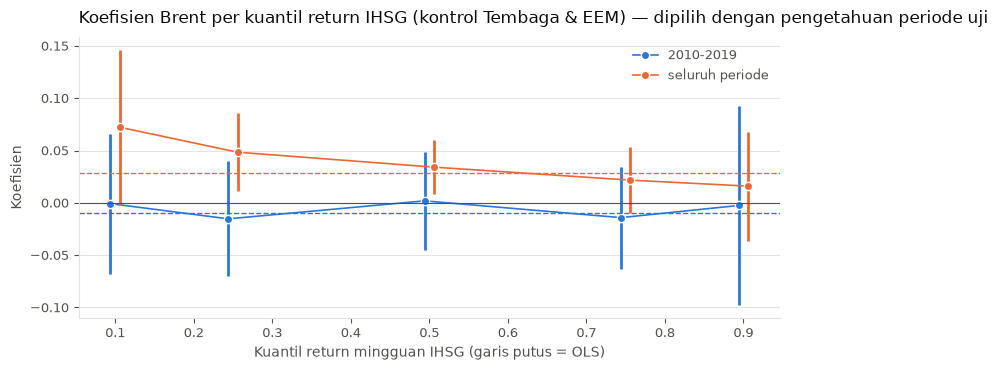

In [9]:
fig = plots.plot_quantile_coefs(qr, brent, f"Koefisien Brent per kuantil return IHSG (kontrol Tembaga & EEM) — {labels[brent]}")
for k, v in spikes.items():
    print(f"{k}: n = {v.attrs['n']}, minggu lonjakan = {v.attrs['n_lonjakan']}")
    display(v.round(4))

## 4. Aset pelindung (deskriptif; Core tidak berubah)

Emas (GC=F), Dollar Index (DX-Y.NYB), dan yield US Treasury 10 tahun (^TNX) diambil dari blok `nanti:` hanya untuk analisis ini. Aturan cleaning Phase 2 berlaku apa adanya: DXY berkategori FX, jadi aturan bad tick FX ikut diterapkan.

Dari sudut pandang investor Indonesia ditambahkan dua pembanding:
- **Emas dalam rupiah** = emas × USD/IDR.
- **Memegang USD** = USD/IDR itu sendiri.

Ada dua pengukuran:
- **Perubahan per episode:** dari sebelum jangkar sampai **titik terendah IHSG**, dan sampai akhir jendela. Yield dalam poin persen.
- **Korelasi mingguan dengan IHSG** di minggu krisis vs minggu normal, untuk melihat apakah tandanya berbalik. Minggu Okt 2026 dikeluarkan dari kedua kelompok.

In [10]:
raw_h = load_prices(havens_tab["ticker"].tolist(), start=dec2["analysis_start"], end=str(trading_days.max().date()), verbose=True)
h_clean, h_log, h_flags = pp.clean_prices(raw_h, havens_tab, cfg)
haven_ids = rcfg["safe_haven_ids"]
print("Dibuang oleh aturan cleaning:", h_log.groupby("id").size().to_dict() or "tidak ada",
      "| ditandai basi:", {k: int(v) for k, v in h_flags.sum().items()} or "tidak ada")
close_all = close.join(ll.drop_flagged(h_clean[haven_ids], h_flags), how="outer")
for gid in rcfg["idr_derived"]:
    close_all[f"{gid}_IDR"] = close_all[gid] * close_all[fx_id]
    names[f"{gid}_IDR"] = f"{names[gid]} (dalam rupiah)"
    transforms[f"{gid}_IDR"] = "log"
names[fx_id] = "Memegang USD (USD/IDR)"
haven_list = haven_ids + [f"{g}_IDR" for g in rcfg["idr_derived"]] + [fx_id]
hret = rg.episode_returns(close_all, target_id, haven_list, transforms, main | desc, window)
hview = hret.pivot_table(index="episode", columns="id", values="ke_titik_terendah_target")[[target_id] + haven_list]
print("Perubahan dari sebelum jangkar sampai titik terendah IHSG (% kecuali UST10Y = poin persen):")
hview.round(3)

Cache: 4 | Download baru: 0 | Gagal: 0
Dibuang oleh aturan cleaning: {'JKSE': 1} | ditandai basi: {'DXY': 0}
Perubahan dari sebelum jangkar sampai titik terendah IHSG (% kecuali UST10Y = poin persen):


id,JKSE,GOLD,DXY,UST10Y,GOLD_IDR,USDIDR
episode,,,,,,
2008,-0.384,-0.028,0.102,0.090,0.102,0.134
2013,-0.196,-0.005,-0.028,0.957,0.099,0.105
2015,-0.132,0.025,-0.012,-0.143,0.113,0.086
2018,-0.063,-0.014,-0.004,-0.033,0.022,0.037
2020,-0.246,0.001,0.055,0.068,0.172,0.171
2022,-0.047,-0.053,0.087,0.958,-0.038,0.016
2026,-0.148,-0.002,-0.000,0.047,0.011,0.013


In [11]:
print("Sampai akhir jendela (+60 hari bursa):")
display(hret.pivot_table(index="episode", columns="id", values="ke_akhir_jendela")[[target_id] + haven_list].round(3))
weekly_all = pp.weekly_returns(close_all[[target_id] + haven_list], transforms)
crisis = rg.crisis_week_mask(weekly_all.index, [wins[k] for k in main])
excl = rg.crisis_week_mask(weekly_all.index, [wins[k] for k in desc])
havens = rg.crisis_weekly_corr(weekly_all.loc[~excl], target_id, haven_list, crisis.loc[~excl])
havens.round(3)

Sampai akhir jendela (+60 hari bursa):


id,JKSE,GOLD,DXY,UST10Y,GOLD_IDR,USDIDR
episode,,,,,,
2008,-0.251,0.131,0.006,-1.656,0.332,0.178
2013,-0.196,-0.005,-0.028,0.957,0.099,0.105
2015,-0.038,-0.015,0.021,0.095,-0.011,0.004
2018,-0.021,0.012,0.005,0.278,0.042,0.030
2020,-0.077,0.041,0.003,-0.046,0.043,0.002
2022,0.026,-0.035,0.065,1.061,-0.033,0.003
2026,-0.091,-0.005,-0.003,0.028,0.005,0.010


,r_krisis,ci_lo_krisis,ci_hi_krisis,n_krisis,r_normal,ci_lo_normal,ci_hi_normal,n_normal,z_fisher,p_fisher,tanda_berbalik,p_fisher_bh
id,,,,,,,,,,,,
GOLD,0.367,0.189,0.521,106,0.132,0.067,0.195,899,2.425,0.015,False,0.038
DXY,-0.463,-0.600,-0.298,106,-0.203,-0.265,-0.139,899,-2.834,0.005,False,0.023
UST10Y,0.031,-0.161,0.221,106,0.109,0.044,0.173,899,-0.754,0.451,False,0.464
GOLD_IDR,0.080,-0.115,0.269,103,0.003,-0.063,0.068,898,0.732,0.464,False,0.464
USDIDR,-0.366,-0.523,-0.186,103,-0.285,-0.344,-0.224,898,-0.863,0.388,False,0.464


## 5. Simpan hasil

Semua tabel disimpan ke `reports/phase5/`.

In [12]:
tables = {"rolling_ringkas_52": shift[52], "rolling_ringkas_156": shift[156], "event_study": es,
          "event_study_median": med, "event_study_sensitivitas_2018feb": es_sens, "event_study_median_sensitivitas": med_sens,
          "brent_kuantil_2010_2019": qr["2010-2019"], "brent_kuantil_penuh": qr["seluruh periode"],
          "brent_lonjakan_2010_2019": spikes["2010-2019"], "brent_lonjakan_penuh": spikes["seluruh periode"],
          "pelindung_per_episode": hret, "pelindung_korelasi_krisis": havens, "pelindung_cleaning_log": h_log}
tables |= {f"rolling_{w}": r for w, r in rolls.items()}
summary = {"episode_utama": main, "sensitivitas": rcfg["sensitivity"], "deskriptif_saja": desc,
           "ambang_lonjakan_brent": thr, "label_brent": labels[brent], "median_episode": med.attrs["episode"]}
paths_out = an.save_tables(output_dir(cfg, "reports", "phase5"), tables, summary)
[p.name for p in paths_out]

['rolling_ringkas_52.csv',
 'rolling_ringkas_156.csv',
 'event_study.csv',
 'event_study_median.csv',
 'event_study_sensitivitas_2018feb.csv',
 'event_study_median_sensitivitas.csv',
 'brent_kuantil_2010_2019.csv',
 'brent_kuantil_penuh.csv',
 'brent_lonjakan_2010_2019.csv',
 'brent_lonjakan_penuh.csv',
 'pelindung_per_episode.csv',
 'pelindung_korelasi_krisis.csv',
 'pelindung_cleaning_log.csv',
 'rolling_52.csv',
 'rolling_156.csv',
 'summary.json']

## Ringkasan insight

Dibangun otomatis dari hasil di atas. Semuanya deskriptif dan tidak mengubah Spesifikasi Phase 6.

In [13]:
display(Markdown(rg.phase5_summary(shift[52], med, med_sens, es, qr, spikes, havens, hret, names, target_id,
                                   brent, labels[brent], list(desc))))

### Ringkasan Phase 5 (DESKRIPTIF, tidak mengubah Spesifikasi Phase 6)

- **Seberapa dalam & cepat** (median 6 episode, tanpa 2026): IHSG drawdown maks -18.0%, titik terendah 28 hari bursa setelah jangkar, return +60 hari -5.8%. Pembanding: iShares MSCI EM -20.1% / 32 hari / -8.0%; KLCI Malaysia -10.0% / 38 hari / -3.4%; Straits Times -14.3% / 22 hari / -7.8%.
  - Sensitivitas jangkar 2018 = 5 Feb: median IHSG drawdown -18.0%, return +60 hari -9.7%.
- **Korelasi saat krisis vs setahun sebelumnya** (median, harian hari yang sama): iShares MSCI EM +0.27 → +0.36; KLCI Malaysia +0.41 → +0.59; Straits Times +0.37 → +0.66.
- **Brent per kuantil (2010-2019, *dipilih dengan pengetahuan periode uji*):** τ=0.1: -0.001 [-0.068, +0.066], τ=0.25: -0.015 [-0.070, +0.040], τ=0.5: +0.002 [-0.045, +0.049], τ=0.75: -0.014 [-0.063, +0.035], τ=0.9: -0.003 [-0.098, +0.093], τ=OLS: -0.010 [-0.054, +0.034].
- **Brent per kuantil (seluruh periode, *dipilih dengan pengetahuan periode uji*):** τ=0.1: +0.072 [-0.002, +0.146], τ=0.25: +0.048 [+0.011, +0.085], τ=0.5: +0.034 [+0.009, +0.060], τ=0.75: +0.022 [-0.010, +0.053], τ=0.9: +0.016 [-0.036, +0.068], τ=OLS: +0.028 [-0.017, +0.073].
  - Minggu lonjakan Brent (2010-2019, 52 minggu): kemiringan total +0.229 [-0.002, +0.460].
  - Minggu lonjakan Brent (seluruh periode, 137 minggu): kemiringan total +0.041 [-0.096, +0.177].
- **Aset pelindung** (median perubahan dari sebelum jangkar sampai titik terendah IHSG): Dollar Index +2.6%; Emas -0.9%; Emas (dalam rupiah) +10.1%; IHSG -16.4%; Memegang USD (USD/IDR) +9.5%; US Treasury 10Y +0.08 pp.
- **Korelasi mingguan dengan IHSG, minggu krisis vs normal:** Emas +0.13 → +0.37; Dollar Index -0.20 → -0.46; US Treasury 10Y +0.11 → +0.03; Emas (dalam rupiah) +0.00 → +0.08; Memegang USD (USD/IDR) -0.29 → -0.37. Tidak ada yang berbalik tanda.